# FoodSure AI - Final Multimodal Fusion and Inference

This notebook evaluates the seven individual/fused modality configurations, compares Logistic Regression, RBF SVM, and Random Forest with stratified five-fold CV, evaluates selected models once on the preserved holdout, and produces reusable model artifacts.

**Scope:** controlled turmeric samples adulterated with wheat flour at seven levels. Independent external validation is required; this prototype is not a certification or evidence of generalization to other adulterants, instruments, or laboratories.

## Method and leakage controls

The experiment runner is implemented in `ml_service/experiments.py` and the serving interface in `ml_service/predictor.py`. Features and targets are reconstructed by joining raw CSVs to the saved sample IDs. The saved target CSVs are audited but not trusted positionally: Notebook 3 filters original raw-table rows with `.isin(...)`, then saves those row-ordered labels separately from the shuffled `train_test_split` ID lists.

Each fold fits a separate scaler for each modality using only fold-training rows. FTIR and Image additionally fit fold-local PCA retaining 90% variance. Fold validation rows are transformed with those learned objects; only then are selected modalities concatenated. Model/config selection uses training CV only. The 70 test IDs are used once after selection.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image as NotebookImage, Markdown

cwd = Path.cwd().resolve()
if cwd.name.lower() == "notebook":
    PROJECT_ROOT = cwd.parent
elif (cwd / "notebook").is_dir():
    PROJECT_ROOT = cwd
else:
    raise FileNotFoundError(f"Run from project root or notebook directory; current directory: {cwd}")
sys.path.insert(0, str(PROJECT_ROOT))
from ml_service.experiments import run_workflow
print("Project root:", PROJECT_ROOT)
print("Existing split:", PROJECT_ROOT / "notebook" / "train_sample_ids.csv", PROJECT_ROOT / "notebook" / "test_sample_ids.csv")

Project root: C:\Users\Vaishnavi Awasthi\Downloads\Multimodal Dataset for Turmeric Adulteration Detec\FoodSure-AI
Existing split: C:\Users\Vaishnavi Awasthi\Downloads\Multimodal Dataset for Turmeric Adulteration Detec\FoodSure-AI\notebook\train_sample_ids.csv C:\Users\Vaishnavi Awasthi\Downloads\Multimodal Dataset for Turmeric Adulteration Detec\FoodSure-AI\notebook\test_sample_ids.csv


## Data verification and full workflow execution

The next cell verifies raw paths, schemas, ID coverage, target agreement across all modalities, split counts, and saved-label ordering. It then executes the full CV, regression, final holdout, artifact-writing, and inference-validation workflow.

In [2]:
results = run_workflow(PROJECT_ROOT)
data = results["data"]
print("Raw data root:", data["raw_root"])
print("Raw CSV paths:", {name: str(path) for name, path in data["paths"].items()})
print("Train/test IDs:", len(data["train_ids"]), len(data["test_ids"]), "overlap:", len(set(data["train_ids"]) & set(data["test_ids"])))
print("Training shapes:", {name: frame.shape for name, frame in data["X_train"].items()})
print("Test shapes:", {name: frame.shape for name, frame in data["X_test"].items()})
print("Training classes:", data["y_train"].value_counts().sort_index().to_dict())
print("Test classes:", data["y_test"].value_counts().sort_index().to_dict())
print("Saved y_train positional differences:", data["saved_train_mismatches"])
print("Saved y_test positional differences:", data["saved_test_mismatches"])
print("Raw target agreement across modalities and saved-label export order: verified")

Raw data root: C:\Users\Vaishnavi Awasthi\Downloads\Multimodal Dataset for Turmeric Adulteration Detec\Multimodal Dataset for Turmeric Adulteration Detec
Raw CSV paths: {'Color': 'C:\\Users\\Vaishnavi Awasthi\\Downloads\\Multimodal Dataset for Turmeric Adulteration Detec\\Multimodal Dataset for Turmeric Adulteration Detec\\Color Measurement\\Hunter_Lab_colorimeter.csv', 'FTIR': 'C:\\Users\\Vaishnavi Awasthi\\Downloads\\Multimodal Dataset for Turmeric Adulteration Detec\\Multimodal Dataset for Turmeric Adulteration Detec\\FTIR Spectroscopy\\FTIR_Data.csv', 'Image': 'C:\\Users\\Vaishnavi Awasthi\\Downloads\\Multimodal Dataset for Turmeric Adulteration Detec\\Multimodal Dataset for Turmeric Adulteration Detec\\Image\\EfficientNetB0_Image_Features\\EfficientNetB0_Image_Features.csv'}
Train/test IDs: 280 70 overlap: 0
Training shapes: {'Color': (280, 46), 'FTIR': (280, 2522), 'Image': (280, 1280)}
Test shapes: {'Color': (70, 46), 'FTIR': (70, 2522), 'Image': (70, 1280)}
Training classes: {0

## Classification cross-validation

This computed comparison contains all requested metrics (mean and population standard deviation), measured runtime stages, and average PCA dimensions where applicable. The fold-level CSV retains the five individual scores for each configuration/model.

,Modalities,Model,Accuracy Mean,Accuracy Std,Macro Precision Mean,Macro Precision Std,Macro Recall Mean,Macro Recall Std,Macro F1 Mean,Macro F1 Std,Classifier Fit/Predict Seconds,Preprocessing Seconds (shared fold cache),Total Pipeline Seconds (measured stages),PCA Components FTIR Mean,PCA Components Image Mean
0,Color,Logistic Regression,0.9714,0.0214,0.9754,0.0186,0.9714,0.0214,0.9710,0.0219,0.1773,0.0576,0.2349,NaN,NaN
1,Color,SVM (RBF),0.9393,0.0368,0.9469,0.0318,0.9393,0.0368,0.9376,0.0391,0.0370,0.0576,0.0946,NaN,NaN
2,Color,Random Forest,0.9429,0.0364,0.9500,0.0374,0.9429,0.0364,0.9421,0.0365,3.0249,0.0576,3.0825,NaN,NaN
3,FTIR,Logistic Regression,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0953,1.5425,1.6377,74.0,NaN
4,FTIR,SVM (RBF),1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0405,1.5425,1.5830,74.0,NaN
5,FTIR,Random Forest,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,4.0520,1.5425,5.5945,74.0,NaN
6,Image,Logistic Regression,0.9464,0.0357,0.9506,0.0331,0.9464,0.0357,0.9456,0.0366,0.1757,0.7507,0.9264,NaN,44.6
7,Image,SVM (RBF),0.9536,0.0290,0.9581,0.0272,0.9536,0.0290,0.9533,0.0291,0.0654,0.7507,0.8161,NaN,44.6
8,Image,Random Forest,0.9000,0.0460,0.9141,0.0378,0.9000,0.0460,0.8968,0.0479,3.7277,0.7507,4.4784,NaN,44.6
9,Color + FTIR,Logistic Regression,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.1294,1.6001,1.7295,74.0,NaN


Fold-level classification results:


,Modalities,Model,Fold,Fit Samples,Validation Samples,Classifier Fit/Predict Seconds,Preprocessing Seconds,PCA Components FTIR,PCA Components Image,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Color,Logistic Regression,1,224,56,0.0467,0.0103,NaN,NaN,1.0000,1.0000,1.0000,1.0000
1,Color,Logistic Regression,2,224,56,0.0328,0.0134,NaN,NaN,0.9464,0.9610,0.9464,0.9445
2,Color,Logistic Regression,3,224,56,0.0318,0.0087,NaN,NaN,0.9821,0.9841,0.9821,0.9821
3,Color,Logistic Regression,4,224,56,0.0309,0.0182,NaN,NaN,0.9821,0.9841,0.9821,0.9821
4,Color,Logistic Regression,5,224,56,0.0352,0.0070,NaN,NaN,0.9464,0.9478,0.9464,0.9462
...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,Color + FTIR + Image,Random Forest,1,224,56,0.7912,0.4895,74.0,44.0,1.0000,1.0000,1.0000,1.0000
101,Color + FTIR + Image,Random Forest,2,224,56,0.7150,0.4372,74.0,45.0,1.0000,1.0000,1.0000,1.0000
102,Color + FTIR + Image,Random Forest,3,224,56,0.9614,0.5727,74.0,45.0,1.0000,1.0000,1.0000,1.0000
103,Color + FTIR + Image,Random Forest,4,224,56,0.7168,0.5094,74.0,44.0,1.0000,1.0000,1.0000,1.0000


Fold-local preprocessing audit (fit row counts, PCA dimensions, variance, time):


,Fold,Modality,Input Features,PCA Components,PCA Explained Variance,Fit And Transform Seconds,Fit Rows,Validation Rows
0,1,Color,46,NaN,NaN,0.0103,224,56
1,1,FTIR,2522,74.0,0.9008,0.3546,224,56
2,1,Image,1280,44.0,0.9002,0.1246,224,56
3,2,Color,46,NaN,NaN,0.0134,224,56
4,2,FTIR,2522,74.0,0.9006,0.2481,224,56
5,2,Image,1280,45.0,0.9017,0.1758,224,56
6,3,Color,46,NaN,NaN,0.0087,224,56
7,3,FTIR,2522,74.0,0.9005,0.4089,224,56
8,3,Image,1280,45.0,0.9020,0.1551,224,56
9,4,Color,46,NaN,NaN,0.0182,224,56


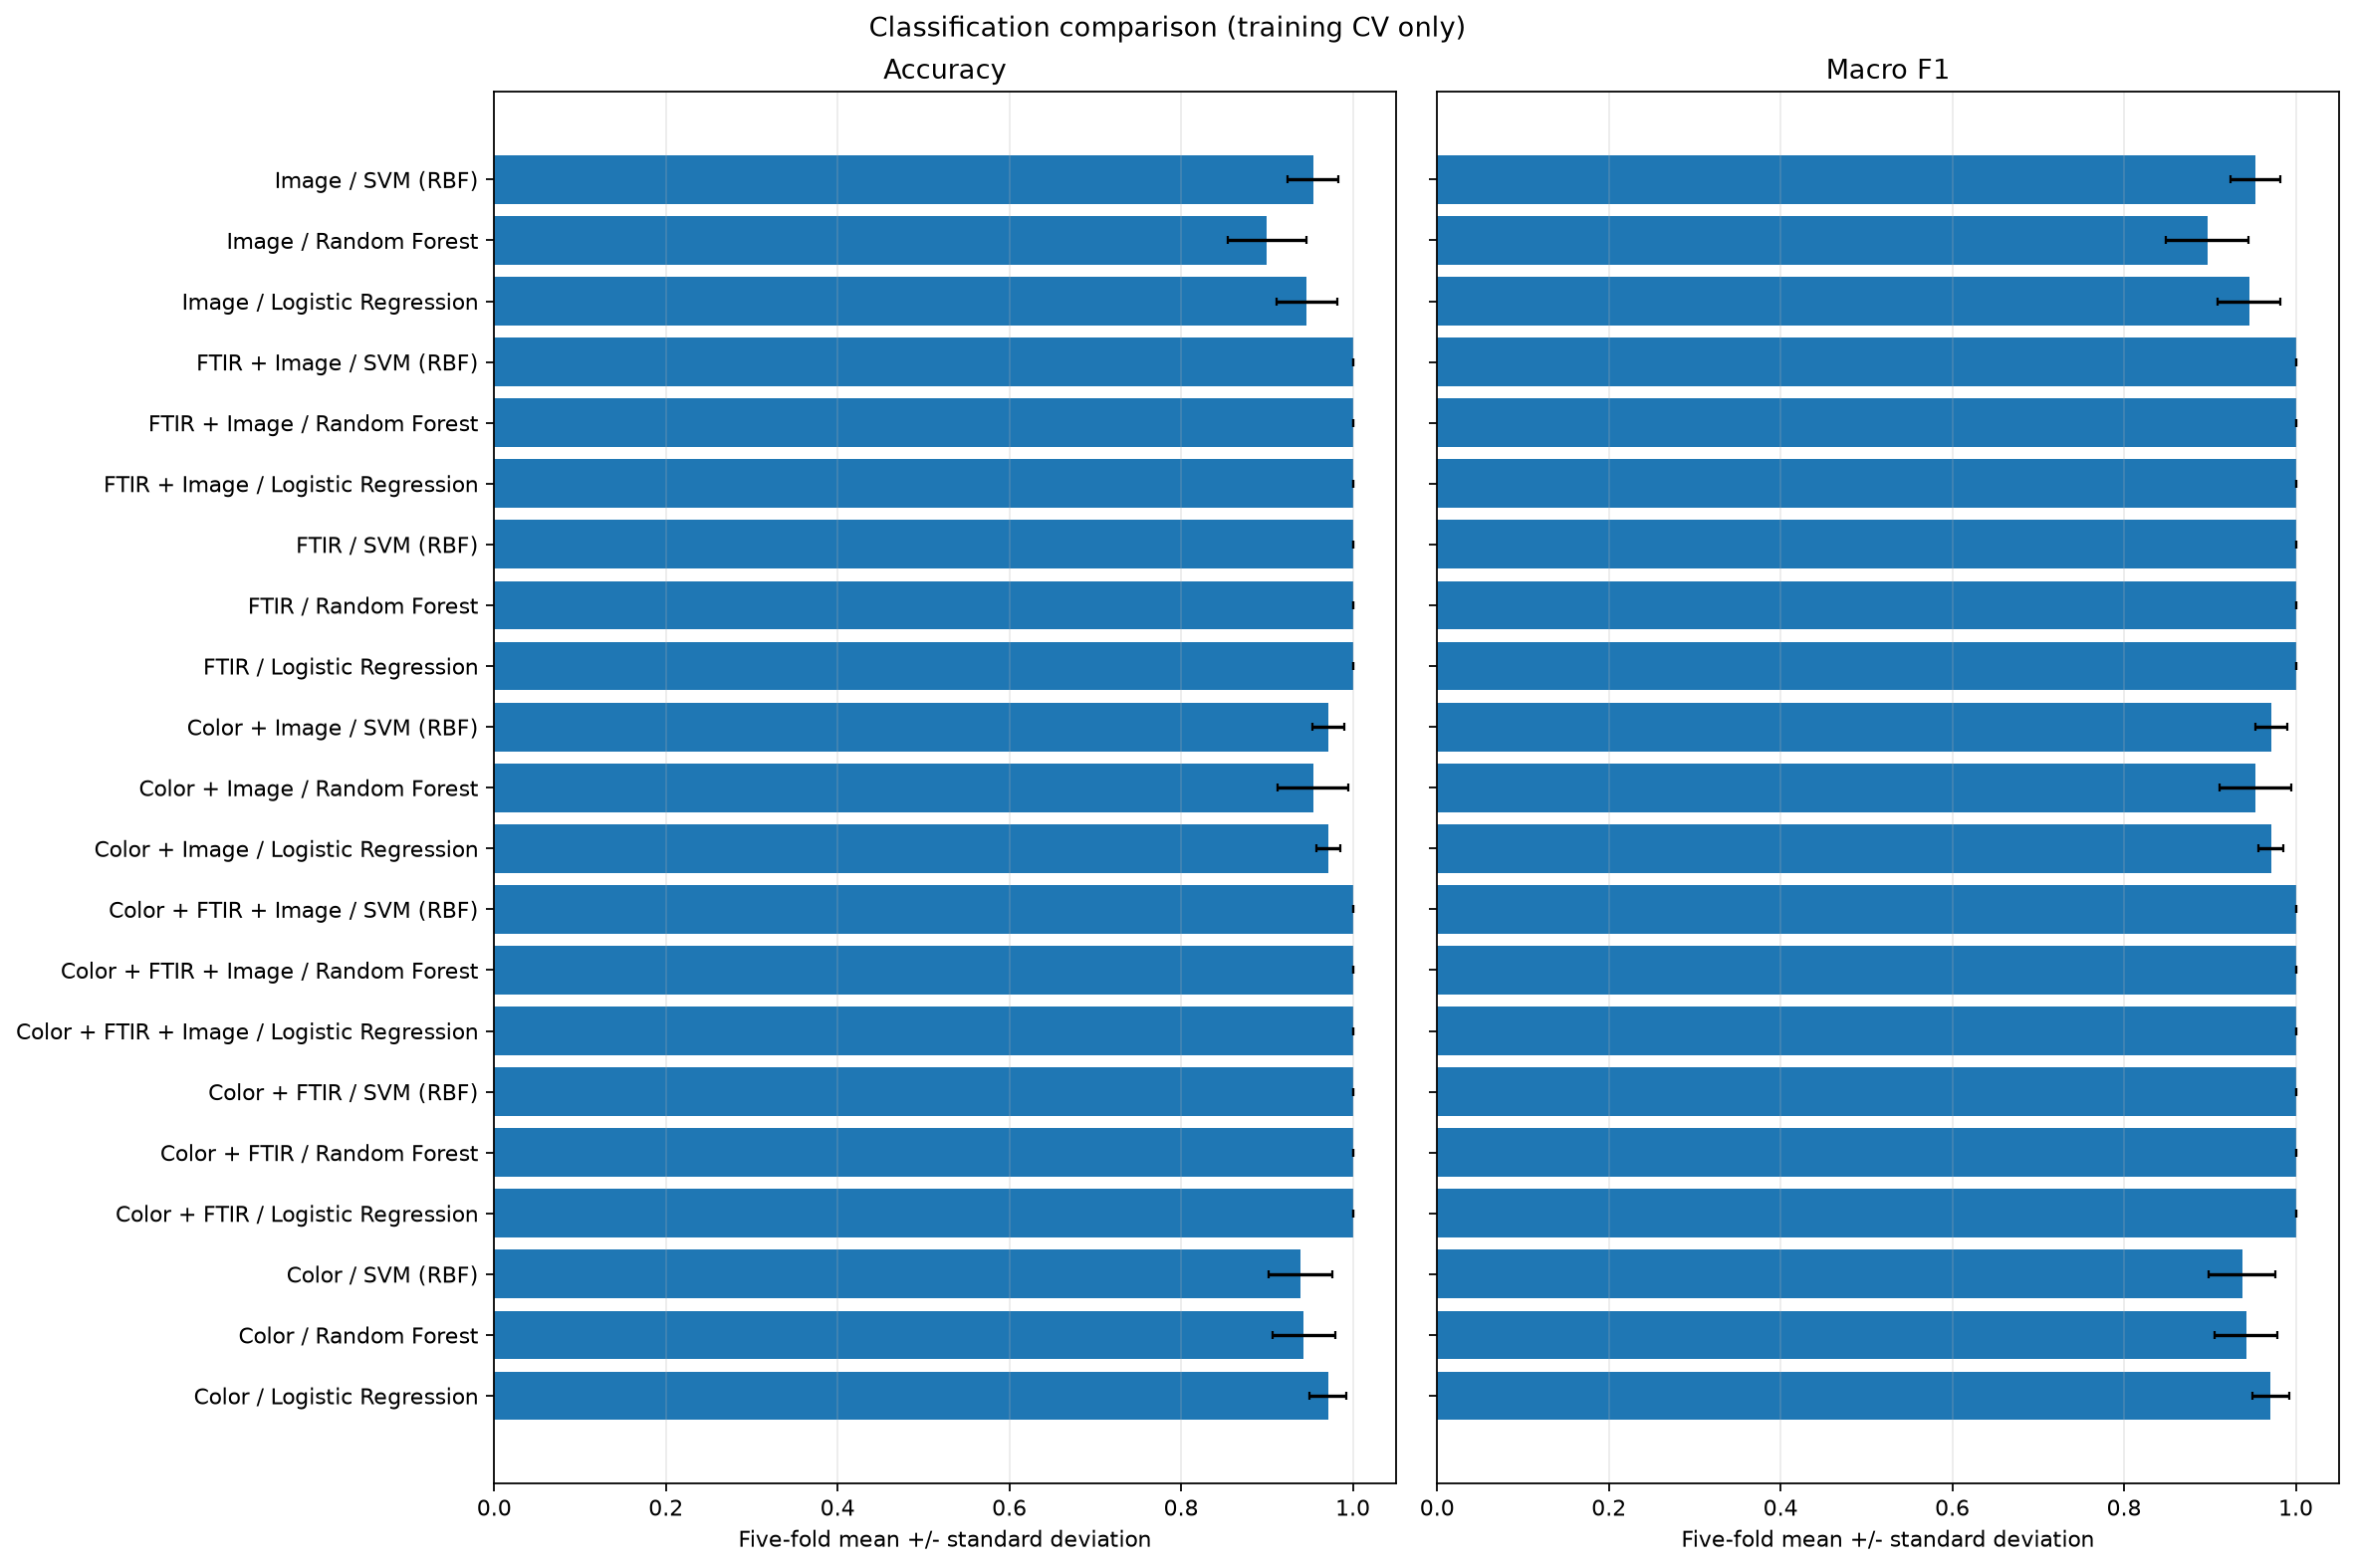

In [3]:
display(results["cv_summary"].round(4))
print("Fold-level classification results:")
display(results["cv_folds"].round(4))
print("Fold-local preprocessing audit (fit row counts, PCA dimensions, variance, time):")
display(results["preprocessing_details"].round(4))
display(NotebookImage(filename=str(results["cv_plot_path"])))

## CV-based model selection and fusion comparison

Preferred model: highest mean macro F1, then lowest macro-F1 fold standard deviation, then accuracy, with simpler modality count preferred on ties. This is descriptive model selection, not a significance test.

In [4]:
selected = results["selected_classifier"]
individual = results["best_individual"]
fusion = results["best_fusion"]
print("Selected:", selected["Modalities"], "/", selected["Model"])
print("Best individual:", individual["Modalities"], "/", individual["Model"], "Macro F1:", round(individual["Macro F1 Mean"], 4))
print("Best fusion:", fusion["Modalities"], "/", fusion["Model"], "Macro F1:", round(fusion["Macro F1 Mean"], 4))
print("Fusion improves over strongest individual:", results["fusion_improves"])
print(results["conclusion"])

Selected: FTIR / Logistic Regression
Best individual: FTIR / Logistic Regression Macro F1: 1.0
Best fusion: Color + FTIR / Logistic Regression Macro F1: 1.0
Fusion improves over strongest individual: False
CV selected FTIR / Logistic Regression (Macro F1 1.0000 +/- 0.0000; accuracy 1.0000 +/- 0.0000). Best individual CV Macro F1 was 1.0000 for FTIR / Logistic Regression; best fusion CV Macro F1 was 1.0000 for Color + FTIR / Logistic Regression. Fusion improves: False. Held-out Macro F1 was 1.0000. Selected regression was Random Forest Regressor (CV MAE 0.0314 +/- 0.0451; test MAE 0.0118). This controlled dataset requires independent external validation.


## Regression: continuous percentage estimates

Notebook 5 reports Linear Regression, SVR, and Random Forest results on precomputed PCA features and one holdout; it does not include fold-local cross-validation. The following Ridge and Random Forest Regressor comparisons use the same fold-specific preprocessing as classification. MAE/RMSE are percentage points; R-squared may be negative and is reported as computed.

In [5]:
print("Regression CV summary:")
display(results["regression_summary"].round(4))
print("Per-fold regression metrics:")
display(results["regression_folds"].round(4))
print("Selected regression model on selected classifier configuration:", results["selected_regression"]["Modalities"], "/", results["selected_regression"]["Model"])

Regression CV summary:


,Modalities,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Fit/Predict Seconds
0,FTIR,Ridge Regression,0.2484,0.0261,0.3310,0.0447,0.9880,0.0031,0.0155
1,FTIR,Random Forest Regressor,0.0314,0.0451,0.1832,0.3246,0.9850,0.0299,7.8215
2,Color + FTIR,Ridge Regression,0.1921,0.0197,0.2575,0.0351,0.9927,0.0019,0.0100
3,Color + FTIR,Random Forest Regressor,0.0421,0.0198,0.1301,0.1004,0.9971,0.0042,12.9648


Per-fold regression metrics:


,Modalities,Model,Fold,MAE,RMSE,R2,Fit/Predict Seconds,PCA Components FTIR,PCA Components Image
0,FTIR,Ridge Regression,1,0.2553,0.3209,0.9889,0.0074,74,NaN
1,FTIR,Ridge Regression,2,0.2799,0.3876,0.9838,0.0023,74,NaN
2,FTIR,Ridge Regression,3,0.2009,0.2531,0.9931,0.0032,74,NaN
3,FTIR,Ridge Regression,4,0.2469,0.3393,0.9876,0.0014,74,NaN
4,FTIR,Ridge Regression,5,0.2591,0.3543,0.9865,0.0012,74,NaN
5,FTIR,Random Forest Regressor,1,0.0086,0.0192,1.0000,0.9228,74,NaN
6,FTIR,Random Forest Regressor,2,0.1217,0.8324,0.9252,1.0661,74,NaN
7,FTIR,Random Forest Regressor,3,0.0099,0.0201,1.0000,2.3142,74,NaN
8,FTIR,Random Forest Regressor,4,0.0086,0.0197,1.0000,1.8987,74,NaN
9,FTIR,Random Forest Regressor,5,0.0083,0.0247,0.9999,1.6198,74,NaN


Selected regression model on selected classifier configuration: FTIR / Random Forest Regressor


## Final held-out test evaluation

Only the CV-selected classifier and its matching CV-selected regressor are evaluated here after refitting preprocessing on all 280 training samples. The confusion matrix and classification report below are computed from the 70 saved test IDs.

,Modalities,Classification Model,Test Accuracy,Test Macro Precision,Test Macro Recall,Test Macro F1,Regression Model,Regression Test MAE,Regression Test RMSE,Regression Test R2,CV Accuracy Mean,CV Accuracy Std,CV Macro F1 Mean,CV Macro F1 Std
0,FTIR,Logistic Regression,1.0,1.0,1.0,1.0,Random Forest Regressor,0.0118,0.0302,0.9999,1.0,0.0,1.0,0.0


Held-out classification report:


,precision,recall,f1-score,support
0%,1.0,1.0,1.0,10.0
1%,1.0,1.0,1.0,10.0
2%,1.0,1.0,1.0,10.0
3%,1.0,1.0,1.0,10.0
5%,1.0,1.0,1.0,10.0
7%,1.0,1.0,1.0,10.0
9%,1.0,1.0,1.0,10.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,70.0
weighted avg,1.0,1.0,1.0,70.0


Held-out confusion matrix:
[[10  0  0  0  0  0  0]
 [ 0 10  0  0  0  0  0]
 [ 0  0 10  0  0  0  0]
 [ 0  0  0 10  0  0  0]
 [ 0  0  0  0 10  0  0]
 [ 0  0  0  0  0 10  0]
 [ 0  0  0  0  0  0 10]]


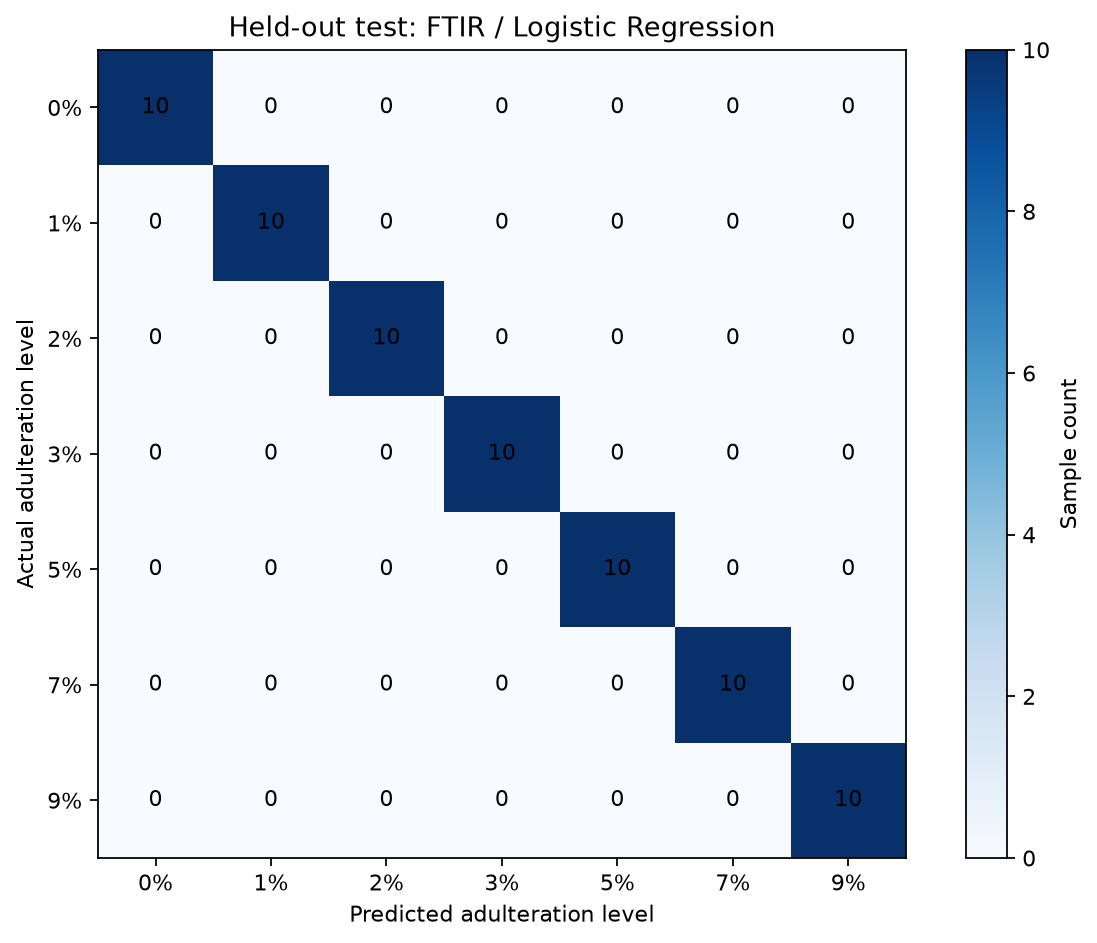

In [6]:
display(results["heldout_results"].round(4))
print("Held-out classification report:")
display(results["heldout_report"].round(4))
print("Held-out confusion matrix:")
print(results["heldout_confusion"])
display(NotebookImage(filename=str(results["confusion_plot_path"])))

## Model artifact and inference validation

The model bundle contains fitted transformations and estimators, not raw or held-out records. `predict_sample` accepts numeric feature vectors in saved feature order; Image means precomputed EfficientNet-B0 embeddings, not raw images. Class probabilities are omitted because calibration was not assessed.

In [7]:
print("Model:", results["model_path"])
print("Metadata:", results["metadata_path"])
print("Valid inference result:", results["valid_prediction"])
print("Invalid input checks (expected validation errors):")
for message in results["invalid_input_results"]:
    print("-", message)
print("All three inference checks passed: artifact reload, valid prediction, missing/wrong-size inputs rejected.")
print("Generated files:", sorted(path.name for path in results["results_dir"].iterdir()))

Model: C:\Users\Vaishnavi Awasthi\Downloads\Multimodal Dataset for Turmeric Adulteration Detec\FoodSure-AI\models\foodsure_multimodal_v1.joblib
Metadata: C:\Users\Vaishnavi Awasthi\Downloads\Multimodal Dataset for Turmeric Adulteration Detec\FoodSure-AI\models\foodsure_multimodal_v1_metadata.json
Valid inference result: {'predicted_class': '7%', 'predicted_percentage': 7.0, 'modality_configuration': ['FTIR'], 'model_version': 'foodsure-ml-v1', 'probabilities': None, 'probability_note': 'Not reported; classifier probabilities were not calibrated.', 'regression_note': 'Unconstrained continuous research estimate; it may fall outside observed target levels.'}
Invalid input checks (expected validation errors):
- Missing required model input modality/modalities: FTIR
- FTIR requires 2522 features in the saved order; received 2521
All three inference checks passed: artifact reload, valid prediction, missing/wrong-size inputs rejected.
Generated files: ['conclusions.txt', 'fusion_classificatio

## Results, limitations, and integration

The CV comparison, fold-level scores, out-of-fold predictions, class-wise report, regression metrics, held-out results, confusion matrix, fitted artifact, metadata, and inference module are written to the project. See the computed conclusion in `results/notebook_09/conclusions.txt`.

The chosen model and modality configuration are based on CV metrics and a simplicity tie-break, not the held-out test result. Fusion is not presumed to improve results. CV variability is not a significance test. The dataset is small and controlled; independent samples, labs, devices, and other adulterants remain unvalidated. The predictor returns model output separately from any AI-generated explanation.